# India Drought Analysis (State: Odisha)
## Notebook 03 (Week 4): Advanced visualizations with Matplotlib, Seaborn, GeoPandas and Plotly (Odisha only)

| | |
|---|---|
| **Course** | CUTM1018 – Data Analysis and Visualization with Python |
| **Faculty** | Chandra Sekhar Jena |
| **Students** | Piyush Patnaik (250301370280), Vegulla Virendra Kaushik (250301370267) |
| **Dataset** | Drought Atlas of India 1901–2025, v2 (Chuphal, Kushwaha, Aadhar & Mishra; IIT Gandhinagar / IIT Jodhpur) – https://zenodo.org/records/20368514 |
| **Scope** | Odisha statewide series + 30 Odisha districts |

### Plan
1. **Odisha district maps (GeoPandas):** recent drought share, long-term trend, district groups and change since 1901–1960, from the atlas shapefiles.
2. **Publication-style charts:** small multiples, drought stripes, stacked area, ridgeline, pairplot, annotated timeline,
   slope chart, lollipop chart.
3. **How stable is the district ranking?** A sensitivity check of the district ranking to the period and the measure.
4. **Interactive Plotly figures** saved as HTML, including the animated district map.

> Figure numbers continue from notebook 02 (fig17 onwards). Every chart is saved at dpi 150 and has a short interpretation written from
> the numbers printed in this notebook.

## 1. Setup: libraries, one colour theme for the whole notebook, and data

In [1]:
from pathlib import Path
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
import matplotlib.patheffects as pe
import seaborn as sns
import geopandas as gpd
import plotly.express as px
from scipy import stats

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 150)

# ---------------- Theme and colours (defined once, used everywhere) ----------------
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"axes.titlesize": 13, "axes.titleweight": "bold", "axes.labelsize": 11,
                     "legend.fontsize": 9, "figure.titlesize": 14, "savefig.dpi": 150, "savefig.bbox": "tight"})

COL = {
    "dry": "#b2182b", "wet": "#2166ac", "neutral": "#9e9e9e", "highlight": "#e66101",
    "early": "#4393c3", "recent": "#d6604d", "odisha": "#762a83",
}
GROUP_COLORS = {"West": "#b2182b", "South": "#e08214", "North & Central": "#1b7837", "Coastal": "#2166ac"}
SEVERITY_COLORS = {"Moderate": "#fdae61", "Severe": "#f46d43", "Extreme": "#a50026"}
CMAP_DIVERGING = "RdBu"      # red = dry, blue = wet (for SPEI values)
CMAP_SEQUENTIAL = "YlOrRd"   # light = few droughts, dark red = many droughts

# Find the project folder: walk up from the current folder until we see data/clean
# (works if Jupyter was started in the project folder or in notebooks/)
PROJECT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "clean").is_dir()), Path.cwd())
if not (PROJECT / "data" / "clean").is_dir():
    raise FileNotFoundError("Cannot find the project folder (the folder that contains data/clean). Open this notebook from inside the "
                            "unzipped project folder and start Jupyter there - a single notebook file cannot run on its own. "
                            "See RUN_ON_YOUR_DEVICE.md.")
CLEAN = PROJECT / "data" / "clean"
RAW = PROJECT / "data" / "raw" / "DroughtAtlas_v2"
FIG = PROJECT / "reports" / "figures"
INTERACTIVE = PROJECT / "reports" / "interactive"
FIG.mkdir(parents=True, exist_ok=True)
INTERACTIVE.mkdir(parents=True, exist_ok=True)

DROUGHT_THRESHOLD = -1.0


def save(fig, name):
    # Save every figure the same way (dpi 150 is set in rcParams above)
    fig.savefig(FIG / name, dpi=150)
    print("saved", name)

# Guard: the district map shapefile comes from the raw atlas data (not included in the run-on-device package)
if not (RAW / "Administrative-Boundaries_Shapefile").is_dir():
    raise RuntimeError("Raw atlas data (district shapefile) not found at " + str(RAW) + ".\n"
                       "Notebook 03 needs it for the maps. See data/raw/HOW_TO_GET_RAW_DATA.txt for how to download it.\n"
                       "You do NOT need it for notebooks 02 and 04 or for the dashboard - they use data/clean/ only.")

In [2]:
# Outputs of notebooks 01 and 02 (Odisha only)
odisha = pd.read_csv(CLEAN / "odisha_month.csv", parse_dates=["date"])
odisha_year = pd.read_csv(CLEAN / "odisha_year.csv")
dist_month = pd.read_csv(CLEAN / "odisha_district_month.csv", parse_dates=["date"])
dist_year = pd.read_csv(CLEAN / "odisha_district_year.csv")
dist_rank = pd.read_csv(CLEAN / "ranking_odisha_districts_1991_2025.csv")
dist_trends = pd.read_csv(CLEAN / "trends_odisha_districts.csv")
lookup_odisha = pd.read_csv(CLEAN / "lookup_odisha_districts_clean.csv")

# Same district groups as notebook 02
ODISHA_GROUPS = {
    "West": ["Bargarh", "Balangir", "Boudh", "Deogarh", "Jharsuguda", "Kalahandi", "Nuapada", "Sambalpur", "Subarnapur", "Sundargarh"],
    "South": ["Koraput", "Malkangiri", "Nabarangpur", "Rayagada", "Gajapati", "Kandhamal"],
    "North & Central": ["Angul", "Dhenkanal", "Keonjhar", "Mayurbhanj", "Jajpur", "Cuttack", "Khordha", "Nayagarh"],
    "Coastal": ["Balasore", "Bhadrak", "Kendrapara", "Jagatsinghpur", "Puri", "Ganjam"],
}
district_group = {d: g for g, names in ODISHA_GROUPS.items() for d in names}
dist_month["group"] = dist_month["district"].map(district_group)
dist_year["group"] = dist_year["district"].map(district_group)
print(odisha.shape, dist_month.shape, dist_rank.shape)

(1500, 12) (45000, 15) (30, 16)


## 2. Odisha district maps with GeoPandas

### 2.1 Loading the shapefile and matching names
The district shapefile has an `ID` column that uses the **same ID numbers** as `India_Districts.xlsx`, so we join on
the ID (safer than joining on names). We still compare the names as a check. The shapefile names are corrupted in one more way than
the Excel files: `>` is used for **A** (e.g. `BIH>R` = Bihar). We keep only the polygons whose `STATE` is ODISHA.

In [3]:
def fix_name(name):
    # Same repair as notebook 01; '>' also stands for 'A' in the shapefile names
    name = str(name).strip().upper().replace("|", "I").replace("@", "U").replace(">", "A")
    return re.sub(r"\s+", " ", name)


SHP = RAW / "Administrative-Boundaries_Shapefile"
dist_shp = gpd.read_file(SHP / "DISTRICT_BOUNDARY.shp")
print("CRS:", dist_shp.crs.name, "| district polygons in the file:", len(dist_shp))
dist_shp["state_fixed"] = dist_shp["STATE"].apply(fix_name)

# Keep Odisha only, then simplify the outlines (tolerance in metres) so maps draw faster
odisha_shp = dist_shp[dist_shp["state_fixed"] == "ODISHA"].copy()
odisha_shp["geometry"] = odisha_shp.geometry.simplify(500)

# Join on ID (= district_id), then check names
odisha_shp["shp_name"] = odisha_shp["District"].apply(fix_name)
odisha_map = odisha_shp.merge(lookup_odisha, left_on="ID", right_on="district_id", how="left")
odisha_map["lookup_name_fixed"] = odisha_map["district_name_raw"].apply(fix_name)
print("Odisha polygons:", len(odisha_map), "| matched to a district_id:", odisha_map["district_id"].notna().sum())
print("Name differences after cleaning:")
display(odisha_map.loc[odisha_map["shp_name"] != odisha_map["lookup_name_fixed"], ["ID", "District", "shp_name", "lookup_name_fixed"]])

# Attach the ranking (notebook 02) and the trend of yearly mean SPEI-1
trend_sp1 = dist_trends[dist_trends["variable"] == "spei1_mean"][["district", "sen_slope_per_decade", "mk_p", "significant"]]
odisha_map = odisha_map.merge(dist_rank[["district", "group", "composite_rank", "drought_share_1991_2025", "change_pp"]],
                              on="district", how="left").merge(trend_sp1, on="district", how="left")
print("Odisha districts with missing values after the joins:", int(odisha_map[["drought_share_1991_2025", "sen_slope_per_decade"]].isna().any(axis=1).sum()))

CRS: LCC_WGS84 | district polygons in the file: 742
Odisha polygons: 30 | matched to a district_id: 30
Name differences after cleaning:


,ID,District,shp_name,lookup_name_fixed


Odisha districts with missing values after the joins: 0


### 2.2 District maps: recent drought share and long-term trend

saved fig17_odisha_district_choropleth.png


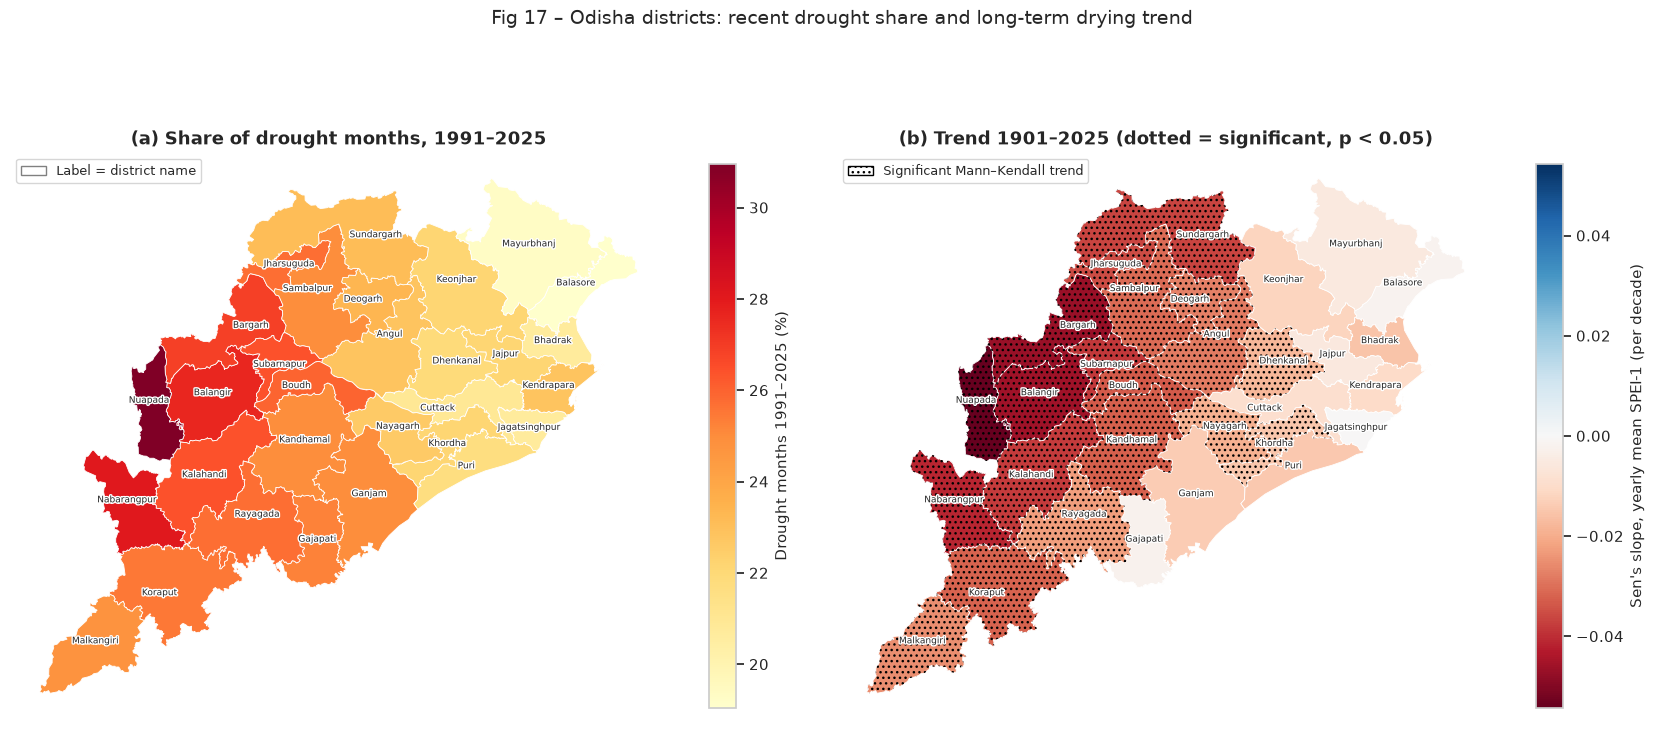

Districts with negative slope: 30 | significant: 19
Not significant: ['Balasore', 'Bhadrak', 'Cuttack', 'Gajapati', 'Ganjam', 'Jagatsinghpur', 'Jajpur', 'Kendrapara', 'Keonjhar', 'Mayurbhanj', 'Puri']
Weakest slope: [['Jagatsinghpur', -0.0002]] | steepest: [['Nuapada', -0.0543]]


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(17, 8.5))

# (a) recent drought share
odisha_map.plot(column="drought_share_1991_2025", cmap=CMAP_SEQUENTIAL, linewidth=0.6, edgecolor="white", ax=axes[0],
                legend=True, legend_kwds={"label": "Drought months 1991–2025 (%)", "shrink": 0.7})
axes[0].set_title("(a) Share of drought months, 1991–2025")

# (b) Sen's slope of yearly mean SPEI-1, significant districts hatched
lim = odisha_map["sen_slope_per_decade"].abs().max()
odisha_map.plot(column="sen_slope_per_decade", cmap=CMAP_DIVERGING, vmin=-lim, vmax=lim, linewidth=0.6,
                edgecolor="white", ax=axes[1], legend=True,
                legend_kwds={"label": "Sen's slope, yearly mean SPEI-1 (per decade)", "shrink": 0.7})
odisha_map[odisha_map["significant"]].plot(ax=axes[1], facecolor="none", edgecolor="black", hatch="...", linewidth=0)
axes[1].set_title("(b) Trend 1901–2025 (dotted = significant, p < 0.05)")
axes[1].legend(handles=[Patch(facecolor="white", edgecolor="black", hatch="...", label="Significant Mann–Kendall trend")],
               loc="upper left")

# District names at a point inside each polygon
for ax in axes:
    for _, r in odisha_map.iterrows():
        p = r.geometry.representative_point()
        ax.annotate(r["district"], (p.x, p.y), ha="center", fontsize=6.5,
                    path_effects=[pe.withStroke(linewidth=2, foreground="white")])   # white outline so names stay readable
    ax.set_axis_off()
axes[0].legend(handles=[Patch(facecolor="white", edgecolor="grey", label="Label = district name")], loc="upper left")
fig.suptitle("Fig 17 – Odisha districts: recent drought share and long-term drying trend")
plt.tight_layout()
save(fig, "fig17_odisha_district_choropleth.png")
plt.show()
print("Districts with negative slope:", int((odisha_map["sen_slope_per_decade"] < 0).sum()), "| significant:", int(odisha_map["significant"].sum()))
print("Not significant:", sorted(odisha_map.loc[~odisha_map["significant"], "district"]))
print("Weakest slope:", odisha_map.nlargest(1, "sen_slope_per_decade")[["district", "sen_slope_per_decade"]].round(4).values.tolist(),
      "| steepest:", odisha_map.nsmallest(1, "sen_slope_per_decade")[["district", "sen_slope_per_decade"]].round(4).values.tolist())

**Figure 17 – Odisha district maps: (a) share of drought months in 1991–2025; (b) Sen's slope of yearly mean SPEI-1, 1901–2025 (dotted = significant Mann–Kendall trend, p < 0.05).**

**Interpretation:** The two maps show the same west-to-east pattern. The west and south-west (Nuapada 31.0%, Nabarangpur 28.1%, Balangir 27.6%) have the most recent drought months, while the north-east coast (Balasore 19.0%, Mayurbhanj 19.3%) has the fewest. All 30 districts have a negative (drying) slope, from −0.054 per decade in Nuapada to almost zero in Jagatsinghpur (−0.0002). The trend is significant in 19 districts. The 11 districts without a significant trend are the 6 coastal districts (Balasore, Bhadrak, Jagatsinghpur, Kendrapara, Puri, Ganjam) and Cuttack, Jajpur, Keonjhar, Mayurbhanj and Gajapati.

### 2.3 District groups and the change since 1901–1960
Left: the four district groups used in the analysis (so that the reader can see where West, South, North & Central and Coastal are).
Right: the change in the share of drought months between 1901–1960 and 1991–2025 (percentage points), with the composite rank written on every district.

saved fig18_odisha_district_groups_and_change.png


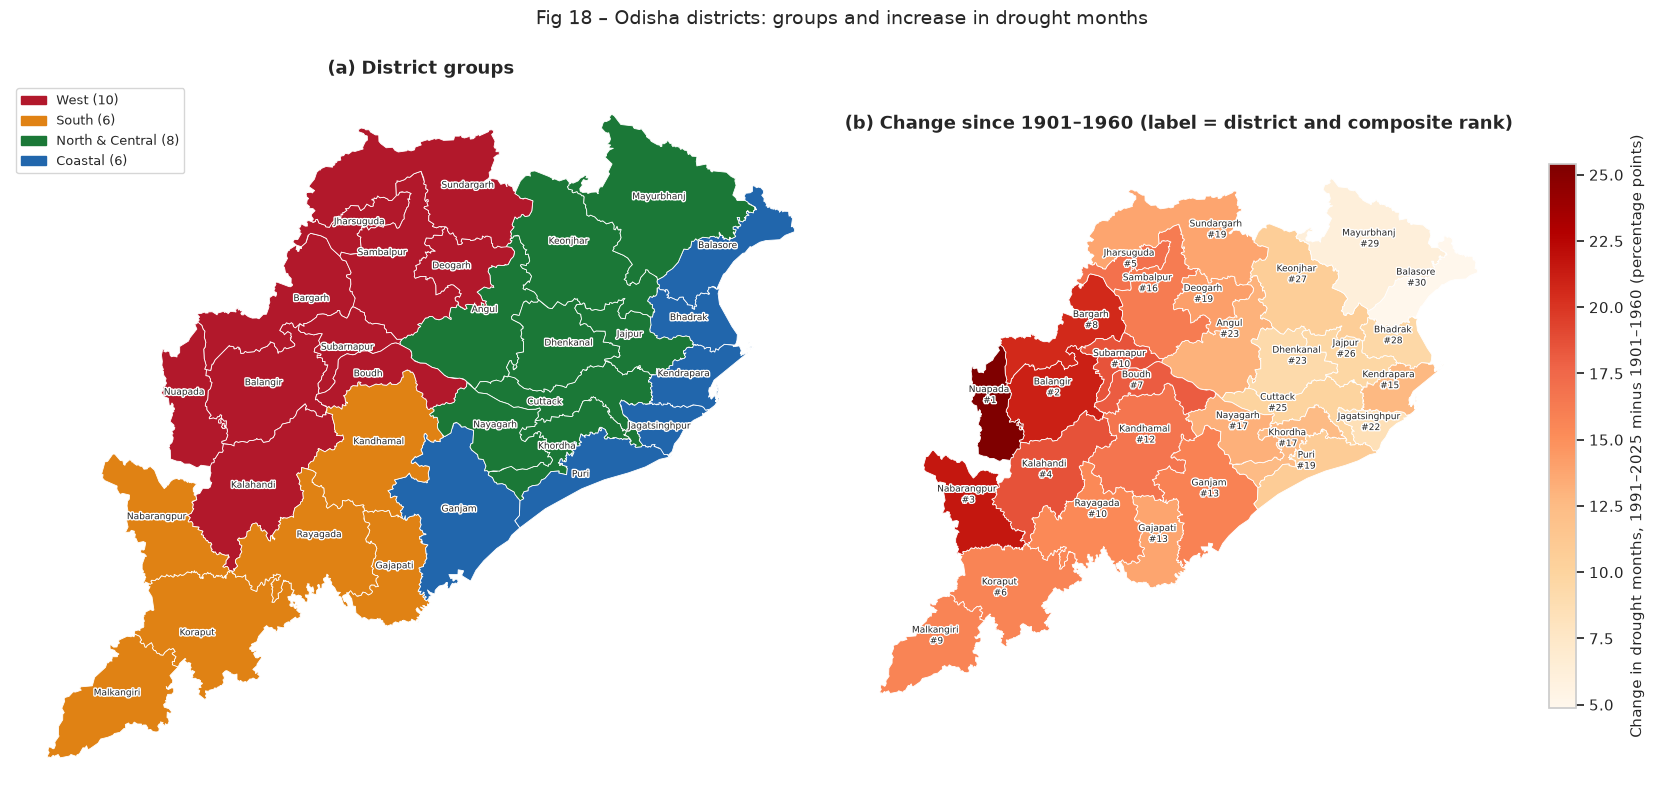

                  min   max  mean
group                            
West             13.8  25.4  18.4
South            13.8  21.6  16.5
North & Central   6.2  13.2  10.6
Coastal           4.9  15.8  10.4


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(17, 8.5))

# (a) groups
odisha_map.plot(color=odisha_map["group"].map(GROUP_COLORS), linewidth=0.6, edgecolor="white", ax=axes[0])
axes[0].set_title("(a) District groups")
axes[0].legend(handles=[Patch(color=c, label=f"{g} ({len(ODISHA_GROUPS[g])})") for g, c in GROUP_COLORS.items()], loc="upper left")

# (b) change in drought share
odisha_map.plot(column="change_pp", cmap="OrRd", linewidth=0.6, edgecolor="white", ax=axes[1], legend=True,
                legend_kwds={"label": "Change in drought months, 1991–2025 minus 1901–1960 (percentage points)", "shrink": 0.7})
axes[1].set_title("(b) Change since 1901–1960 (label = district and composite rank)")

for ax, with_rank in zip(axes, [False, True]):
    for _, r in odisha_map.iterrows():
        p = r.geometry.representative_point()
        text = f"{r['district']}\n#{int(r['composite_rank'])}" if with_rank else r["district"]
        ax.annotate(text, (p.x, p.y), ha="center", fontsize=6.5,
                    path_effects=[pe.withStroke(linewidth=2, foreground="white")])
    ax.set_axis_off()
fig.suptitle("Fig 18 – Odisha districts: groups and increase in drought months")
plt.tight_layout()
save(fig, "fig18_odisha_district_groups_and_change.png")
plt.show()
print(odisha_map.groupby("group")["change_pp"].agg(["min", "max", "mean"]).round(1).loc[list(GROUP_COLORS)])

**Figure 18 – Odisha district maps: (a) the four district groups; (b) change in the share of drought months, 1991–2025 minus 1901–1960 (with composite rank).**

**Interpretation:** The increase is biggest in the west and south: West districts rose by 13.8 to 25.4 points (mean +18.4) and South districts by 13.8 to 21.6 (mean +16.5). North & Central districts rose by 6.2 to 13.2 (mean +10.6) and Coastal districts by 4.9 to 15.8 (mean +10.4). Ganjam (+15.8, joint 13th in the ranking) is the one coastal district that behaves more like the south; Balasore (+4.9) has the smallest increase of all 30. The low composite ranks (#1–#10) sit together in the west and south-west, and the high ranks (#25–#30) in the north and north-east (Cuttack, Jajpur, Keonjhar, Bhadrak, Mayurbhanj, Balasore).

## 3. Publication-style charts

### 3.1 Small multiples: yearly SPEI-12 for each Odisha district group
Each panel shows the December SPEI-12 (dryness of the whole calendar year) for every district in the group (thin lines) and the
group average (thick line).

saved fig19_facet_spei12_district_groups.png


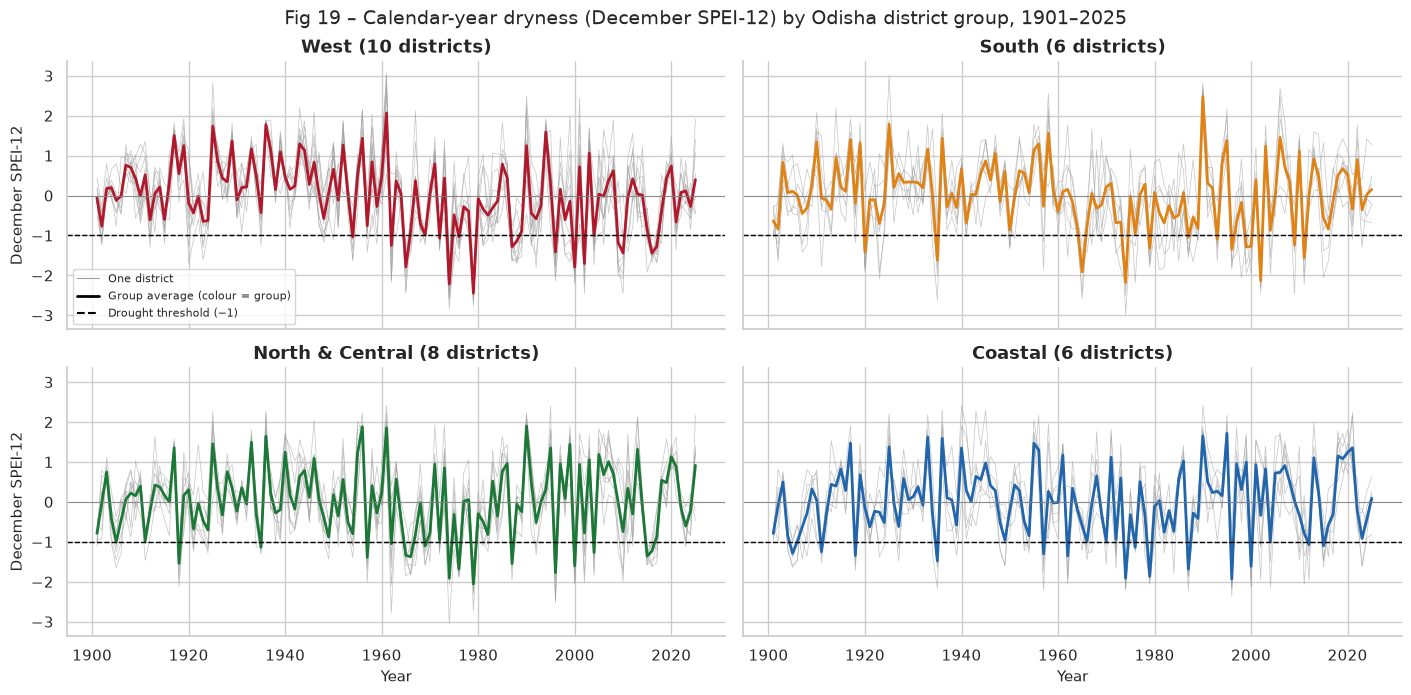

period,1901-1960,1961-1990,1991-2025
group,,,
West,1,8,7
South,2,4,7
North & Central,4,8,5
Coastal,5,5,4


In [6]:
group_order = ["West", "South", "North & Central", "Coastal"]
g = sns.FacetGrid(dist_year, col="group", col_wrap=2, col_order=group_order, height=3.4, aspect=2.1, sharey=True)
g.map_dataframe(sns.lineplot, x="year", y="annual_spei12_dec", units="district", estimator=None,
                color=COL["neutral"], linewidth=0.5, alpha=0.6)
for ax, grp in zip(g.axes.flat, group_order):
    mean_line = dist_year[dist_year["group"] == grp].groupby("year")["annual_spei12_dec"].mean()
    ax.plot(mean_line.index, mean_line.values, color=GROUP_COLORS[grp], linewidth=2)
    ax.axhline(DROUGHT_THRESHOLD, color="black", linestyle="--", linewidth=1)
    ax.axhline(0, color="grey", linewidth=0.6)
    ax.set_title(f"{grp} ({len(ODISHA_GROUPS[grp])} districts)")
g.set_axis_labels("Year", "December SPEI-12")
g.axes.flat[0].legend(handles=[Line2D([0], [0], color=COL["neutral"], linewidth=0.8, label="One district"),
                               Line2D([0], [0], color="black", linewidth=2, label="Group average (colour = group)"),
                               Line2D([0], [0], color="black", linestyle="--", label="Drought threshold (−1)")],
                      loc="lower left", fontsize=8)
g.figure.suptitle("Fig 19 – Calendar-year dryness (December SPEI-12) by Odisha district group, 1901–2025", y=1.02)
save(g.figure, "fig19_facet_spei12_district_groups.png")
plt.show()

# Numbers for the interpretation: years with group-average SPEI-12 <= -1 in each period
grp_mean = dist_year.groupby(["group", "year"])["annual_spei12_dec"].mean().reset_index()
grp_mean["period"] = np.where(grp_mean["year"] <= 1960, "1901-1960", np.where(grp_mean["year"] >= 1991, "1991-2025", "1961-1990"))
(grp_mean[grp_mean["annual_spei12_dec"] <= -1].groupby(["group", "period"]).size().unstack(fill_value=0)
 .reindex(columns=["1901-1960", "1961-1990", "1991-2025"], fill_value=0).loc[group_order])

**Figure 19 – December SPEI-12 (calendar-year dryness) for every district (grey) and the group average (colour), one panel per district group, 1901–2025.**

**Interpretation:** All four groups go up and down together in the big years, but the West panel changes most after 1960. Its group average was at or below −1 in only 1 year in 1901–1960, against 8 years in 1961–1990 and 7 years in 1991–2025. The South group also rose (2 → 4 → 7 years), while North & Central (4 → 8 → 5) and Coastal (5 → 5 → 4) did not rise recently. These periods have different lengths (60, 30 and 35 years), so the West's 1 year in 60 against 7 years in 35 is an even bigger jump than the raw counts suggest.

### 3.2 Drought stripes
Inspired by the "warming stripes" idea: one vertical stripe per year, coloured by the yearly mean SPEI-1 (red = dry year, blue = wet year).
The top stripe is the Odisha statewide series; the four below are the district-group averages.

saved fig20_drought_stripes.png


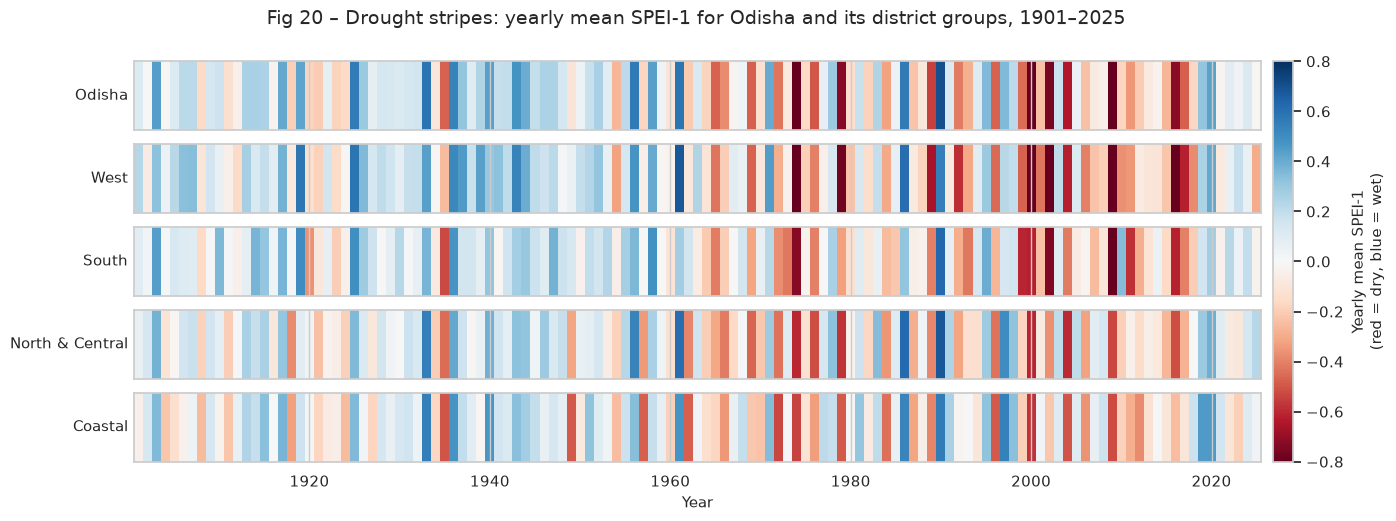

Odisha          : years with mean SPEI-1 < -0.3 -> 1901-1960: 1, 1961-1990: 9, 1991-2025: 10
West            : years with mean SPEI-1 < -0.3 -> 1901-1960: 1, 1961-1990: 7, 1991-2025: 15
South           : years with mean SPEI-1 < -0.3 -> 1901-1960: 2, 1961-1990: 8, 1991-2025: 9
North & Central : years with mean SPEI-1 < -0.3 -> 1901-1960: 4, 1961-1990: 10, 1991-2025: 8
Coastal         : years with mean SPEI-1 < -0.3 -> 1901-1960: 4, 1961-1990: 9, 1991-2025: 6
Odisha driest years (mean SPEI-1): [[1974.0, -0.87], [2009.0, -0.83], [2000.0, -0.8], [2002.0, -0.76], [1979.0, -0.73]]
Odisha mean SPEI-1 2019-2025: [[2019.0, 0.32], [2020.0, 0.43], [2021.0, -0.02], [2022.0, 0.09], [2023.0, 0.03], [2024.0, 0.12], [2025.0, -0.01]]


In [7]:
group_year = dist_year.groupby(["group", "year"])["spei1_mean"].mean().unstack(0)
stripe_data = {"Odisha": odisha_year.set_index("year")["spei1_mean"]}
for grp in group_order:
    stripe_data[grp] = group_year[grp]

fig, axes = plt.subplots(len(stripe_data), 1, figsize=(15, 5.2), sharex=True)
for ax, (label, series) in zip(axes, stripe_data.items()):
    im = ax.imshow(series.values[np.newaxis, :], aspect="auto", cmap=CMAP_DIVERGING, vmin=-0.8, vmax=0.8,
                   extent=[series.index.min() - 0.5, series.index.max() + 0.5, 0, 1])
    ax.set_yticks([])
    ax.set_ylabel(label, rotation=0, ha="right", va="center", fontsize=11)
axes[-1].set_xlabel("Year")
cbar = fig.colorbar(im, ax=axes, orientation="vertical", fraction=0.02, pad=0.01)
cbar.set_label("Yearly mean SPEI-1\n(red = dry, blue = wet)")
fig.suptitle("Fig 20 – Drought stripes: yearly mean SPEI-1 for Odisha and its district groups, 1901–2025")
save(fig, "fig20_drought_stripes.png")
plt.show()

# Numbers for the interpretation
for label, series in stripe_data.items():
    print(f"{label:16s}: years with mean SPEI-1 < -0.3 -> 1901-1960: {(series.loc[:1960] < -0.3).sum()}, "
          f"1961-1990: {(series.loc[1961:1990] < -0.3).sum()}, 1991-2025: {(series.loc[1991:] < -0.3).sum()}")
print("Odisha driest years (mean SPEI-1):", odisha_year.nsmallest(5, "spei1_mean")[["year", "spei1_mean"]].round(2).values.tolist())
print("Odisha mean SPEI-1 2019-2025:", odisha_year[odisha_year["year"] >= 2019][["year", "spei1_mean"]].round(2).values.tolist())

**Figure 20 – Drought stripes: one coloured stripe per year, yearly mean SPEI-1 for Odisha (top) and the four district-group averages; red = dry, blue = wet.**

**Interpretation:** The Odisha bar is mostly blue until about 1960 and turns much redder after that. Years with mean SPEI-1 below −0.3 were rare in 1901–1960 (1 year), but there were 9 in 1961–1990 and 10 in 1991–2025. The darkest Odisha stripes are 1974 (−0.87), 2009 (−0.83), 2000 (−0.80), 2002 (−0.76) and 1979 (−0.73). The West stripe is the one that keeps getting redder: 1, 7 and 15 such years in the three periods, against 4, 9 and 6 for the Coastal group and 4, 10 and 8 for North & Central (South: 2, 8, 9). Odisha's stripes become lighter after about 2018: none of the years 2019–2025 has a mean SPEI-1 below −0.3.

### 3.3 Severity classes per decade (stacked area)
Share of all Odisha district-months (30 districts) in each drought class, per decade. The 1900s cover 1901–1909 and the 2020s cover 2020–2025.

saved fig21_severity_stacked_area.png


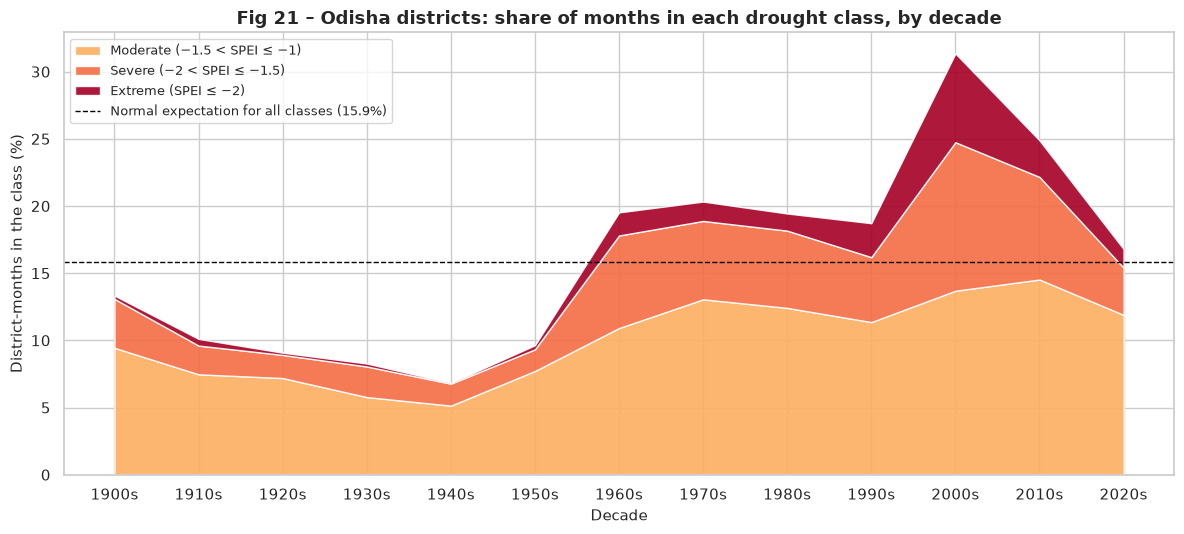

severity,Moderate,Severe,Extreme,total
decade,,,,
1900,9.4,3.6,0.2,13.3
1910,7.5,2.1,0.5,10.1
1920,7.2,1.7,0.2,9.1
1930,5.8,2.3,0.2,8.3
1940,5.1,1.6,0.1,6.8
1950,7.7,1.6,0.3,9.6
1960,10.9,6.9,1.7,19.5
1970,13.1,5.8,1.4,20.3
1980,12.4,5.8,1.3,19.4


In [8]:
sev = (pd.crosstab(dist_month["decade"], dist_month["severity"], normalize="index") * 100)[["Moderate", "Severe", "Extreme"]]
fig, ax = plt.subplots(figsize=(12, 5.5))
ax.stackplot(sev.index, sev["Moderate"], sev["Severe"], sev["Extreme"],
             labels=["Moderate (−1.5 < SPEI ≤ −1)", "Severe (−2 < SPEI ≤ −1.5)", "Extreme (SPEI ≤ −2)"],
             colors=[SEVERITY_COLORS["Moderate"], SEVERITY_COLORS["Severe"], SEVERITY_COLORS["Extreme"]], alpha=0.9)
ax.axhline(15.87, color="black", linestyle="--", linewidth=1, label="Normal expectation for all classes (15.9%)")
ax.set_xticks(sev.index)
ax.set_xticklabels([f"{d}s" for d in sev.index])
ax.set_title("Fig 21 – Odisha districts: share of months in each drought class, by decade")
ax.set_xlabel("Decade")
ax.set_ylabel("District-months in the class (%)")
ax.legend(loc="upper left")
plt.tight_layout()
save(fig, "fig21_severity_stacked_area.png")
plt.show()
sev.assign(total=sev.sum(axis=1)).round(1)

**Figure 21 – Share of Odisha district-months in each drought class (Moderate, Severe, Extreme), by decade (stacked area).**

**Interpretation:** From the 1900s to the 1950s, total drought months stayed below the 15.9% normal level (6.8–13.3%), and extreme months were almost absent (0.1–0.5%). From the 1960s to the 1990s, the total stayed between 18.7% and 20.3%. The 2000s were the worst decade: 31.4% of all district-months were in drought, with severe (11.1%) and extreme (6.6%) months much more common. The 2010s were still high (24.9%), while the 2020s so far are near normal (16.8%). So the 2000s were not only more frequent drought but also more *intense* drought.

### 3.4 Ridgeline plot: how the Odisha SPEI-1 distribution moved by decade

saved fig22_ridgeline_decades.png


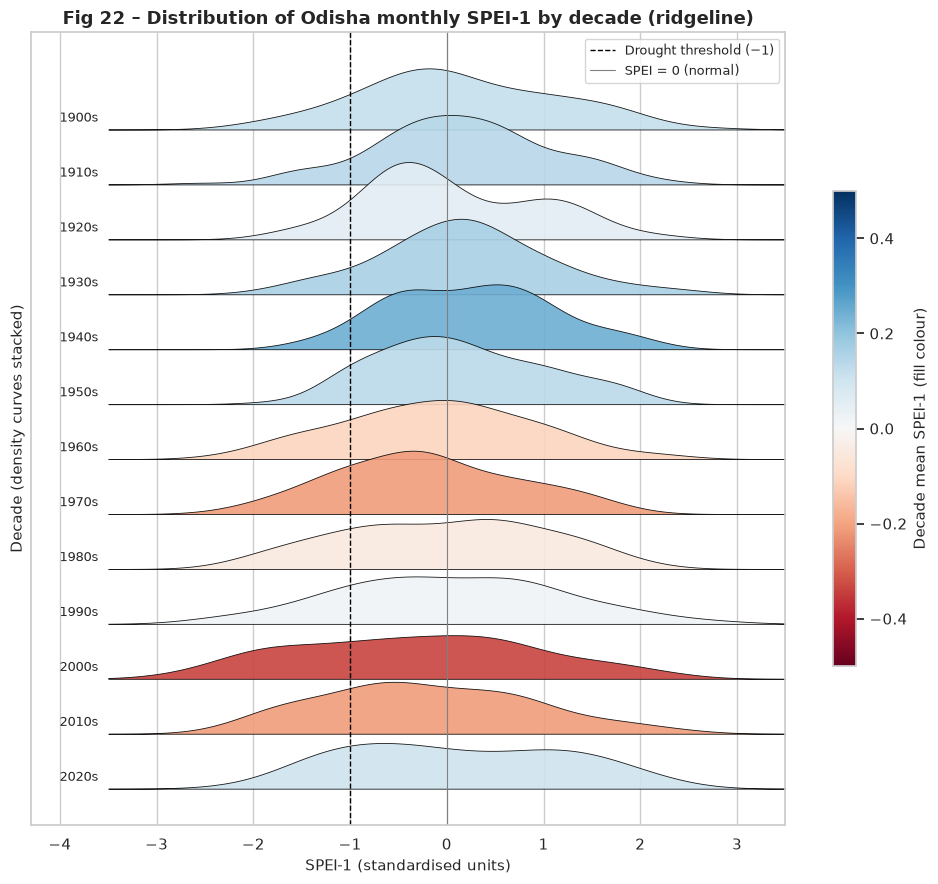

decade,1900,1910,1920,1930,1940,1950,1960,1970,1980,1990,2000,2010,2020
mean,0.12,0.14,0.05,0.16,0.24,0.14,-0.11,-0.21,-0.05,0.02,-0.34,-0.21,0.10
median,-0.02,0.11,-0.14,0.18,0.27,0.09,-0.11,-0.25,-0.02,-0.13,-0.31,-0.36,0.02
std,1.00,0.89,0.88,0.86,0.83,0.85,0.98,0.94,1.04,1.13,1.21,1.07,1.11


In [9]:
decades = sorted(odisha["decade"].unique())
xgrid = np.linspace(-3.5, 3.5, 300)
dec_means = odisha.groupby("decade")["spei_1"].mean()
color_norm = mcolors.Normalize(vmin=-0.5, vmax=0.5)
cmap = plt.get_cmap(CMAP_DIVERGING)

fig, ax = plt.subplots(figsize=(10, 9))
for i, dec in enumerate(decades):
    values = odisha.loc[odisha["decade"] == dec, "spei_1"]
    density = stats.gaussian_kde(values)(xgrid)
    offset = (len(decades) - 1 - i) * 0.35          # newest decade at the bottom
    ax.fill_between(xgrid, offset, offset + density, color=cmap(color_norm(dec_means[dec])), alpha=0.9,
                    edgecolor="black", linewidth=0.6)
    ax.text(-3.6, offset + 0.05, f"{dec}s", ha="right", fontsize=9)
ax.axvline(DROUGHT_THRESHOLD, color="black", linestyle="--", linewidth=1, label="Drought threshold (−1)")
ax.axvline(0, color="grey", linewidth=0.8, label="SPEI = 0 (normal)")
sm_ = plt.cm.ScalarMappable(cmap=cmap, norm=color_norm)
fig.colorbar(sm_, ax=ax, shrink=0.6, label="Decade mean SPEI-1 (fill colour)")
ax.set_yticks([])
ax.set_xlim(-4.3, 3.5)
ax.set_title("Fig 22 – Distribution of Odisha monthly SPEI-1 by decade (ridgeline)")
ax.set_xlabel("SPEI-1 (standardised units)")
ax.set_ylabel("Decade (density curves stacked)")
ax.legend(loc="upper right")
plt.tight_layout()
save(fig, "fig22_ridgeline_decades.png")
plt.show()
odisha.groupby("decade")["spei_1"].agg(["mean", "median", "std"]).round(2).T

**Figure 22 – Ridgeline plot: distribution (density curve) of Odisha monthly SPEI-1 in each decade; fill colour = decade mean.**

**Interpretation:** The early decades (1900s–1950s) are blue and centred on positive values (decade means +0.05 to +0.24) with fairly narrow curves (std 0.83–1.00). The 2000s curve is the flattest and furthest to the left (mean −0.34, std 1.21), so it has a long tail of very dry months beyond −2. The 1970s (−0.21) and 2010s (−0.21) are also shifted towards drought. The 2020s move back towards normal (mean +0.10), but the curve is still wide (std 1.11), so month-to-month swings remain larger than in the early 1900s.

### 3.5 Pairplot of district drought measures
One point per Odisha district. Measures: drought share in 1901–1960 and 1991–2025, change between them, and the trend (Sen's slope)
of yearly mean SPEI-1.

saved fig23_pairplot_district_metrics.png


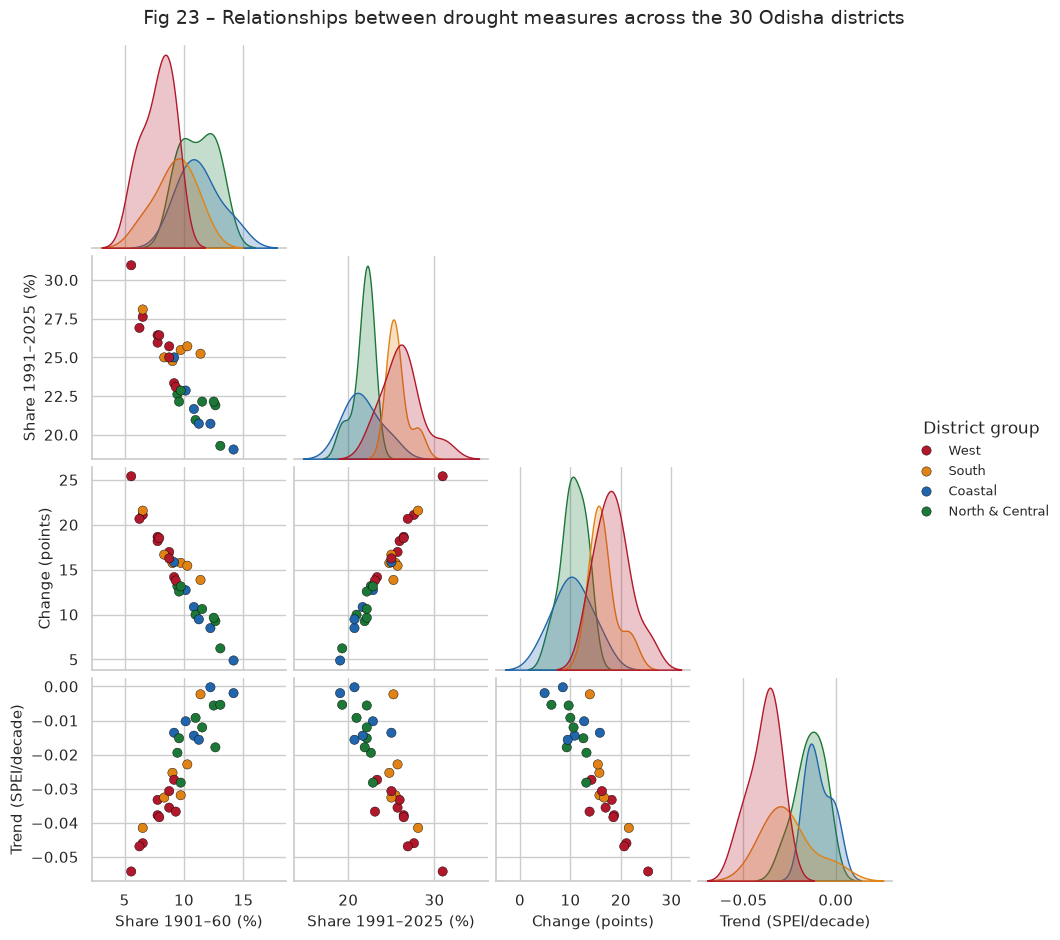

,Share 1901–60 (%),Share 1991–2025 (%),Change (points),Trend (SPEI/decade)
Share 1901–60 (%),1.00,-0.86,-0.95,0.89
Share 1991–2025 (%),-0.86,1.00,0.97,-0.83
Change (points),-0.95,0.97,1.00,-0.87
Trend (SPEI/decade),0.89,-0.83,-0.87,1.00


In [10]:
pair_df = dist_rank[["district", "group", "drought_share_1901_1960", "drought_share_1991_2025", "change_pp"]].merge(
    trend_sp1[["district", "sen_slope_per_decade"]], on="district")
pair_df = pair_df.rename(columns={"drought_share_1901_1960": "Share 1901–60 (%)", "drought_share_1991_2025": "Share 1991–2025 (%)",
                                  "change_pp": "Change (points)", "sen_slope_per_decade": "Trend (SPEI/decade)"})
pp = sns.pairplot(pair_df.drop(columns="district"), hue="group", palette=GROUP_COLORS, corner=True,
                  plot_kws={"s": 45, "edgecolor": "black", "linewidth": 0.3}, diag_kind="kde", height=2.3)
pp.figure.suptitle("Fig 23 – Relationships between drought measures across the 30 Odisha districts", y=1.02)
pp._legend.set_title("District group")
save(pp.figure, "fig23_pairplot_district_metrics.png")
plt.show()
pair_df.drop(columns=["district", "group"]).corr(method="spearman").round(2)

**Figure 23 – Pair plot of four drought measures for the 30 Odisha districts, coloured by district group (diagonal = density per group).**

**Interpretation:** The measures are strongly linked. Districts with more recent drought months also had the biggest increase (Spearman 0.97) and the steepest drying trend (−0.83). The colours separate clearly: West districts (red) sit in the corner with low early share, high recent share and the steepest negative trend, while Coastal and North & Central districts form the opposite corner. Early share and recent share are strongly negatively related (Spearman −0.86). Part of this is built into SPEI: each district's full 1901–2025 record is standardised, so a district with few droughts early on must have more later. This is why we compare *change* and *trend* rather than reading early and recent shares as independent facts.

### 3.6 Annotated timeline of Odisha monsoon droughts
Bars show the September SPEI-4 (the June–September monsoon) for every year, coloured by severity class. Years at or below −1.5
(severe or extreme) are labelled with the year and value. Labels come only from the data.

saved fig24_odisha_monsoon_timeline.png


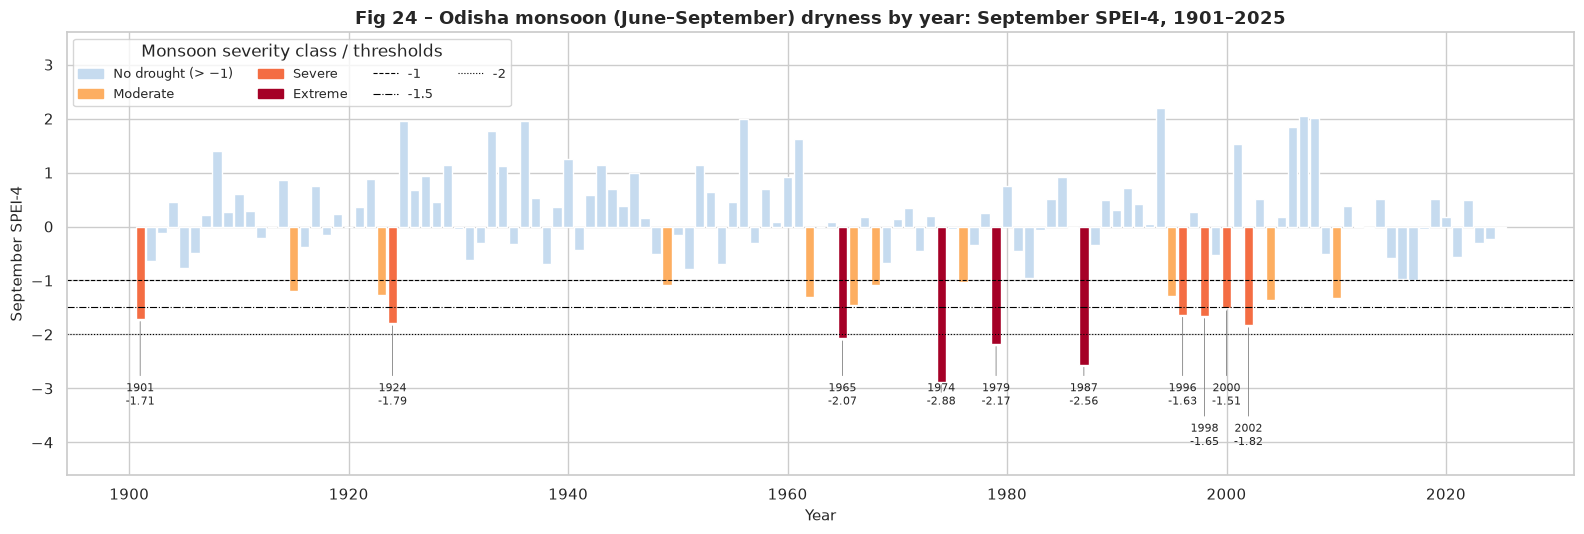

Odisha September SPEI-4 in 1972: -0.45
Last year with SPEI-4 <= -1.5: 2002
Monsoon-drought years (<= -1) per period: {Interval(1900, 1960, closed='right'): 5, Interval(1960, 1990, closed='right'): 8, Interval(1990, 2025, closed='right'): 7}


,year,monsoon_spei4_sep,monsoon_severity
73,1974,-2.88,Extreme
86,1987,-2.56,Extreme
78,1979,-2.17,Extreme
64,1965,-2.07,Extreme
101,2002,-1.82,Severe
23,1924,-1.79,Severe
0,1901,-1.71,Severe
97,1998,-1.65,Severe
95,1996,-1.63,Severe
99,2000,-1.51,Severe


In [11]:
tl = odisha_year[["year", "monsoon_spei4_sep", "monsoon_severity"]].copy()
bar_colors = tl["monsoon_severity"].map({**SEVERITY_COLORS, "No drought": "#c6dbef"})

fig, ax = plt.subplots(figsize=(16, 5.5))
ax.bar(tl["year"], tl["monsoon_spei4_sep"], color=bar_colors, width=0.85)
for level, ls in [(-1, "--"), (-1.5, "-."), (-2, ":")]:
    ax.axhline(level, color="black", linestyle=ls, linewidth=0.8)
labelled = tl[tl["monsoon_spei4_sep"] <= -1.5].sort_values("year")
# When labelled years are close together (e.g. 1996, 1998, 2000, 2002), alternate the label height so they do not overlap
level, last_year = 0, -100
for _, r in labelled.iterrows():
    level = (level + 1) % 2 if r["year"] - last_year < 4 else 0
    last_year = r["year"]
    ax.annotate(f"{int(r['year'])}\n{r['monsoon_spei4_sep']:.2f}", xy=(r["year"], r["monsoon_spei4_sep"]),
                xytext=(r["year"], -3.3 - 0.75 * level), ha="center", fontsize=8,
                arrowprops={"arrowstyle": "-", "color": "grey", "linewidth": 0.6})
labelled = labelled.sort_values("monsoon_spei4_sep")
handles = [Patch(color="#c6dbef", label="No drought (> −1)")] + [Patch(color=c, label=k) for k, c in SEVERITY_COLORS.items()]
handles += [Line2D([0], [0], color="black", linestyle=ls, linewidth=0.8, label=f"{lvl}")
            for lvl, ls in [(-1, "--"), (-1.5, "-."), (-2, ":")]]
ax.legend(handles=handles, loc="upper left", ncol=4, title="Monsoon severity class / thresholds")
ax.set_ylim(-4.6, 3.6)
ax.set_title("Fig 24 – Odisha monsoon (June–September) dryness by year: September SPEI-4, 1901–2025")
ax.set_xlabel("Year")
ax.set_ylabel("September SPEI-4")
plt.tight_layout()
save(fig, "fig24_odisha_monsoon_timeline.png")
plt.show()
print("Odisha September SPEI-4 in 1972:", tl.loc[tl["year"] == 1972, "monsoon_spei4_sep"].round(2).item())
print("Last year with SPEI-4 <= -1.5:", int(labelled["year"].max()))
print("Monsoon-drought years (<= -1) per period:", odisha_year.groupby("period" if "period" in odisha_year else pd.cut(odisha_year["year"], [1900, 1960, 1990, 2025]))["monsoon_drought"].sum().to_dict())
labelled.round(2)

**Figure 24 – Odisha monsoon dryness (September SPEI-4, covering June–September) for every year, coloured by severity class; years with SPEI-4 ≤ −1.5 are labelled with their value.**

**Interpretation:** The labels come only from the data. The four extreme monsoon years are 1974 (−2.88), 1987 (−2.56), 1979 (−2.17) and 1965 (−2.07). After them come the severe years 2002 (−1.82), 1924 (−1.79), 1901 (−1.71), 1998 (−1.65), 1996 (−1.63) and 2000 (−1.51). 1901, 1965, 1974, 1979, 1987 and 2002 are also on the list of major *all-India* drought years in the [NIDM Drought Manual (2009, Table "Meteorological history of droughts in India")](https://nidm.gov.in/pdf/manuals/drought_manual.pdf), so Odisha's worst monsoon years mostly match well-known national drought years. Not every national drought hit Odisha hard, though: 1972, a severe all-India drought, has an Odisha September SPEI-4 of only −0.45. The late 1990s cluster (1996, 1998, 2000, 2002) is the only time Odisha had four severe monsoon years in seven years. No monsoon year since 2003 reached −1.5, and there were 5 monsoon-drought years (SPEI-4 ≤ −1) in 1901–1960, 8 in 1961–1990 and 7 in 1991–2025, which fits notebook 02's result that the recent drying comes mostly from outside the monsoon.

### 3.7 Slope chart: Odisha districts, 1901–1960 vs 1991–2025

saved fig25_slope_chart_districts.png


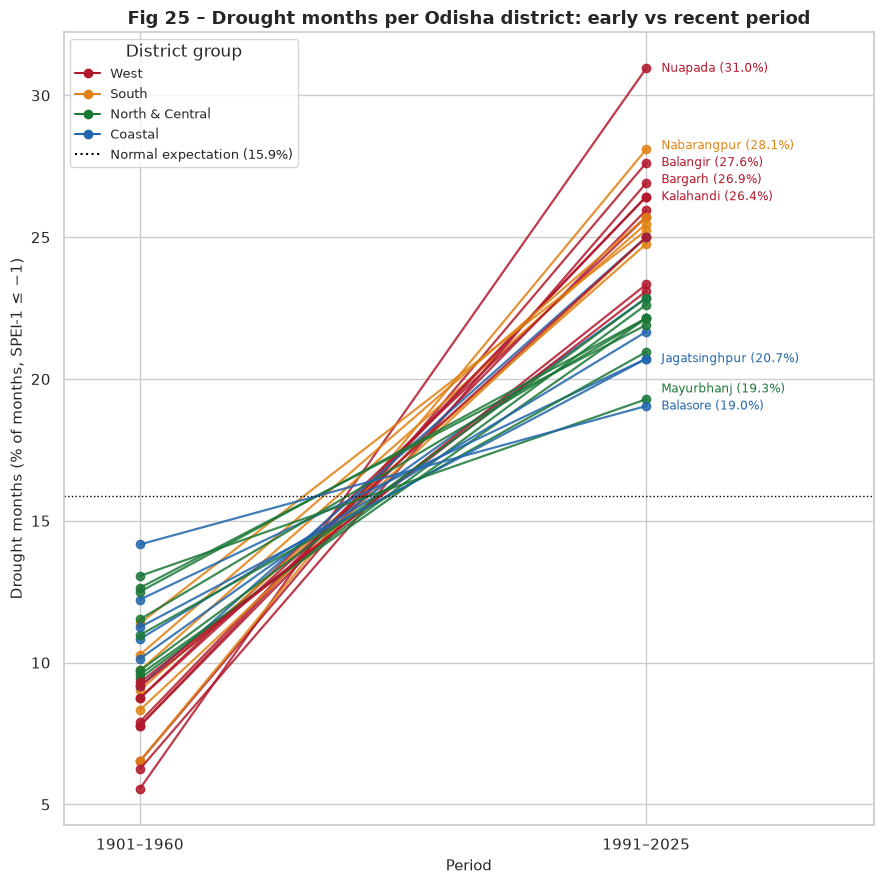

Districts whose share went DOWN: 0
Rank correlation between early and recent share (Spearman): -0.86
[['Balasore', 14.2, 19.0], ['Mayurbhanj', 13.1, 19.3], ['Dhenkanal', 12.6, 21.9]]
[['Nuapada', 5.6, 31.0], ['Bargarh', 6.2, 26.9], ['Balangir', 6.5, 27.6]]


In [12]:
slope = dist_rank[["district", "group", "drought_share_1901_1960", "drought_share_1991_2025"]]
fig, ax = plt.subplots(figsize=(9, 9))
for _, r in slope.iterrows():
    ax.plot([0, 1], [r["drought_share_1901_1960"], r["drought_share_1991_2025"]], color=GROUP_COLORS[r["group"]],
            marker="o", linewidth=1.6, alpha=0.85)
# Label the top 5 and bottom 3 districts in 1991-2025 (labelling all 30 would overlap)
to_label = pd.concat([slope.nlargest(5, "drought_share_1991_2025"), slope.nsmallest(3, "drought_share_1991_2025")])
to_label = to_label.sort_values("drought_share_1991_2025")
label_y = -100
for _, r in to_label.iterrows():
    label_y = max(r["drought_share_1991_2025"], label_y + 0.6)   # keep labels at least 0.6 points apart
    ax.text(1.03, label_y, f"{r['district']} ({r['drought_share_1991_2025']:.1f}%)",
            va="center", fontsize=8.5, color=GROUP_COLORS[r["group"]])
ax.axhline(15.87, color="black", linestyle=":", linewidth=1)
ax.set_xticks([0, 1])
ax.set_xticklabels(["1901–1960", "1991–2025"])
ax.set_xlim(-0.15, 1.45)
ax.set_title("Fig 25 – Drought months per Odisha district: early vs recent period")
ax.set_xlabel("Period")
ax.set_ylabel("Drought months (% of months, SPEI-1 ≤ −1)")
ax.legend(handles=[Line2D([0], [0], color=c, marker="o", label=g) for g, c in GROUP_COLORS.items()]
          + [Line2D([0], [0], color="black", linestyle=":", label="Normal expectation (15.9%)")],
          title="District group", loc="upper left")
plt.tight_layout()
save(fig, "fig25_slope_chart_districts.png")
plt.show()
print("Districts whose share went DOWN:", (slope["drought_share_1991_2025"] < slope["drought_share_1901_1960"]).sum())
print("Rank correlation between early and recent share (Spearman):",
      round(stats.spearmanr(slope["drought_share_1901_1960"], slope["drought_share_1991_2025"]).statistic, 2))
print(slope.nlargest(3, "drought_share_1901_1960")[["district", "drought_share_1901_1960", "drought_share_1991_2025"]].round(1).values.tolist())
print(slope.nsmallest(3, "drought_share_1901_1960")[["district", "drought_share_1901_1960", "drought_share_1991_2025"]].round(1).values.tolist())

**Figure 25 – Slope chart: share of drought months in 1901–1960 (left) and 1991–2025 (right) for each Odisha district, coloured by group.**

**Interpretation:** Every one of the 30 lines goes up, so no district had fewer drought months recently. The lines also cross: the West districts start lowest (Nuapada 5.6%, Bargarh 6.2%, Balangir 6.5%) and finish highest (Nuapada 31.0%, Balangir 27.6%, Bargarh 26.9%). Districts that started highest, like Balasore (14.2%), Mayurbhanj (13.1%) and Dhenkanal (12.6%), finish with 19.0%, 19.3% and 21.9%. The rank order is almost reversed (Spearman −0.86 between the two periods), which is the 'crossing over' that the West-vs-Coastal tests in notebook 02 found.

### 3.8 Lollipop chart: the "dry-season" rise in every district
In notebook 02 we found that Odisha's recent increase in drought months came mostly from the dry season. Here we compare, for every district,
the change in drought share (1991–2025 minus 1901–1960) in the **dry season (October–May)** and in the **monsoon (June–September)**.

Districts where the dry-season rise is larger than the monsoon rise: 30 of 30


saved fig26_lollipop_season_change.png


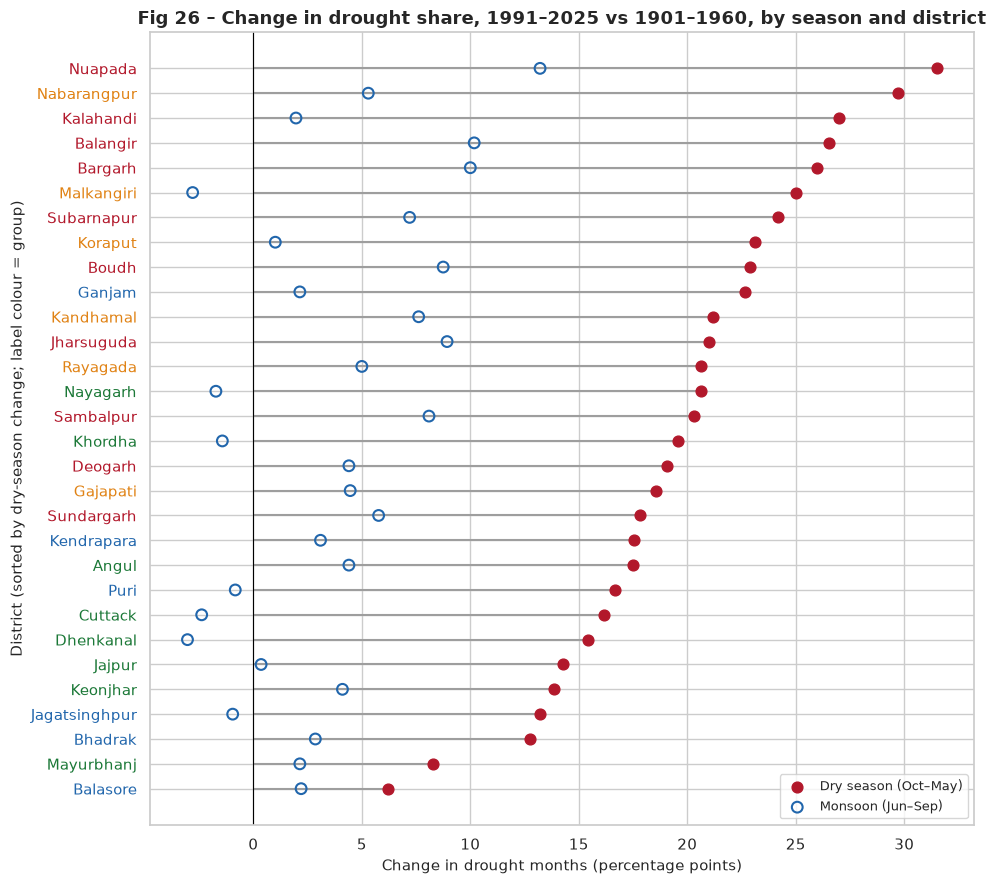

Odisha statewide: {'dry_season': 21.3, 'monsoon': 3.4}
Monsoon change range: -3.0 to 13.2
Dry-season change range: 6.2 to 31.5


part,dry_season,monsoon,group
district,,,
Balasore,6.2,2.2,Coastal
Mayurbhanj,8.3,2.1,North & Central
Bhadrak,12.8,2.9,Coastal
Bargarh,26.0,10.0,West
Balangir,26.5,10.2,West
Kalahandi,27.0,2.0,West
Nabarangpur,29.7,5.3,South
Nuapada,31.5,13.2,West


In [13]:
dm = dist_month.copy()
dm["part"] = np.where(dm["month"].between(6, 9), "monsoon", "dry_season")
early = dm[dm["year"] <= 1960].groupby(["district", "part"])["drought"].mean().unstack() * 100
recent = dm[dm["year"] >= 1991].groupby(["district", "part"])["drought"].mean().unstack() * 100
season_change = (recent - early).sort_values("dry_season")
season_change["group"] = season_change.index.map(district_group)
print("Districts where the dry-season rise is larger than the monsoon rise:",
      (season_change["dry_season"] > season_change["monsoon"]).sum(), "of", len(season_change))

fig, ax = plt.subplots(figsize=(10, 9))
y = np.arange(len(season_change))
ax.hlines(y, 0, season_change["dry_season"], color=COL["neutral"], linewidth=1.5)
ax.scatter(season_change["dry_season"], y, color=COL["dry"], s=60, zorder=3, label="Dry season (Oct–May)")
ax.scatter(season_change["monsoon"], y, facecolor="none", edgecolor=COL["wet"], s=60, linewidth=1.5, zorder=3,
           label="Monsoon (Jun–Sep)")
ax.axvline(0, color="black", linewidth=0.8)
ax.set_yticks(y)
ax.set_yticklabels(season_change.index)
for tick, grp in zip(ax.get_yticklabels(), season_change["group"]):
    tick.set_color(GROUP_COLORS[grp])
ax.set_title("Fig 26 – Change in drought share, 1991–2025 vs 1901–1960, by season and district")
ax.set_xlabel("Change in drought months (percentage points)")
ax.set_ylabel("District (sorted by dry-season change; label colour = group)")
ax.legend(loc="lower right")
plt.tight_layout()
save(fig, "fig26_lollipop_season_change.png")
plt.show()
print("Odisha statewide:", ((odisha[odisha['year']>=1991].assign(p=lambda d: np.where(d['month'].between(6,9),'monsoon','dry_season')).groupby('p')['drought'].mean()
      - odisha[odisha['year']<=1960].assign(p=lambda d: np.where(d['month'].between(6,9),'monsoon','dry_season')).groupby('p')['drought'].mean())*100).round(1).to_dict())
print("Monsoon change range:", season_change["monsoon"].min().round(1), "to", season_change["monsoon"].max().round(1))
print("Dry-season change range:", season_change["dry_season"].min().round(1), "to", season_change["dry_season"].max().round(1))
season_change.round(1).head(3).append(season_change.round(1).tail(5)) if hasattr(pd.DataFrame, "append") else pd.concat([season_change.round(1).head(3), season_change.round(1).tail(5)])

**Figure 26 – Lollipop chart: change in drought share (1991–2025 minus 1901–1960) for the dry season (Oct–May, filled red) and the monsoon (Jun–Sep, open blue) in each Odisha district.**

**Interpretation:** In **all 30 districts** the dry season became drier by more than the monsoon did. For Odisha as a whole the change is +21.3 points in the dry season and only +3.4 in the monsoon, which matches notebook 02's finding that Odisha's monsoon indicator has no significant trend. The dry-season rise ranges from +6.2 points (Balasore) to +31.5 (Nuapada); the monsoon change ranges from −3.0 to +13.2. The West districts are the ones where the monsoon also contributed (Nuapada +13.2, Balangir +10.2, Bargarh +10.0), while in a district like Kalahandi the dry season rose by +27.0 and the monsoon by only +2.0.

### 3.9 How stable is the district ranking?
The composite ranking of notebook 02 uses 1991–2025. Here we rank the 30 districts again under different **periods** (using SPEI-1 drought share)
and different **measures** (for 1991–2025). Rank 1 = most drought-prone.

In [14]:
scenarios = {}
# Different periods, same measure (share of months with SPEI-1 <= -1)
for y0, y1 in [(1981, 2025), (1991, 2025), (2001, 2025), (1991, 2010), (1991, 2020), (2011, 2025)]:
    part = dist_month[(dist_month["year"] >= y0) & (dist_month["year"] <= y1)]
    scenarios[f"SPEI-1 share {y0}–{y1}"] = part.groupby("district")["drought"].mean().rank(ascending=False, method="min")

# Same measure, but leave out the worst decade (is one decade carrying the result?)
part = dist_month[(dist_month["year"] >= 1991) & ~dist_month["year"].between(2000, 2009)]
scenarios["SPEI-1 share 1991–2025 without the 2000s"] = part.groupby("district")["drought"].mean().rank(ascending=False, method="min")

# Different measures for 1991-2025
recent_m = dist_month[dist_month["year"] >= 1991]
for col in ["spei_4", "spei_12"]:
    scenarios[f"{col.upper().replace('_', '-')} share 1991–2025"] = (
        (recent_m[col] <= -1).groupby(recent_m["district"]).mean().rank(ascending=False, method="min"))
scenarios["Mean SPEI-1 1991–2025 (lowest = 1)"] = recent_m.groupby("district")["spei_1"].mean().rank(method="min")
scenarios["Composite rank 1991–2025"] = dist_rank.set_index("district")["composite_rank"]
scenarios["Change vs 1901–1960"] = dist_rank.set_index("district")["change_pp"].rank(ascending=False, method="min")

rank_table = pd.DataFrame(scenarios).T.astype(int)
print("Number of scenarios:", len(rank_table))
for d in ["Nuapada", "Nabarangpur", "Balangir", "Bargarh", "Balasore"]:
    print(f"{d:12s} best rank {rank_table[d].min():2d} | worst rank {rank_table[d].max():2d} | median {rank_table[d].median():.1f} | 1st in {(rank_table[d] == 1).sum()} scenarios")
print("\nScenarios where Nuapada is 1st:", (rank_table["Nuapada"] == 1).sum(), "of", len(rank_table))
print("Districts that are 1st in at least one scenario:", sorted(set(rank_table.columns[(rank_table == 1).any()])))
# Spearman correlation of every scenario with the composite rank
corr_comp = rank_table.apply(lambda row: stats.spearmanr(row, rank_table.loc["Composite rank 1991–2025"]).statistic, axis=1)
print("\nSpearman with the composite rank: min", corr_comp.drop("Composite rank 1991–2025").min().round(2), "| max", corr_comp.drop("Composite rank 1991–2025").max().round(2))
print(corr_comp.round(2).to_string())

Number of scenarios: 12
Nuapada      best rank  1 | worst rank  2 | median 1.0 | 1st in 11 scenarios
Nabarangpur  best rank  2 | worst rank 28 | median 2.5 | 1st in 0 scenarios
Balangir     best rank  2 | worst rank  6 | median 3.0 | 1st in 0 scenarios
Bargarh      best rank  1 | worst rank 10 | median 4.0 | 1st in 1 scenarios
Balasore     best rank 18 | worst rank 30 | median 29.5 | 1st in 0 scenarios

Scenarios where Nuapada is 1st: 11 of 12
Districts that are 1st in at least one scenario: ['Bargarh', 'Nuapada']

Spearman with the composite rank: min 0.41 | max 0.95
SPEI-1 share 1981–2025                      0.93
SPEI-1 share 1991–2025                      0.93
SPEI-1 share 2001–2025                      0.89
SPEI-1 share 1991–2010                      0.90
SPEI-1 share 1991–2020                      0.95
SPEI-1 share 2011–2025                      0.69
SPEI-1 share 1991–2025 without the 2000s    0.75
SPEI-4 share 1991–2025                      0.64
SPEI-12 share 1991–2025          

saved fig27_ranking_sensitivity_heatmap.png


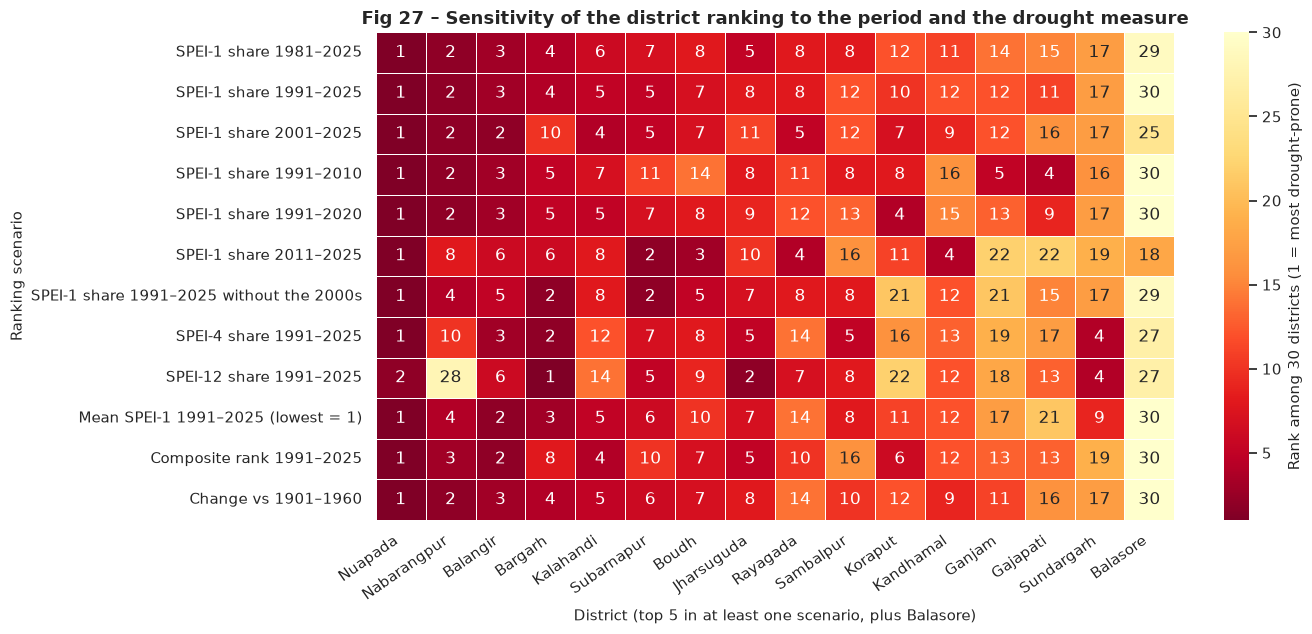

district,Nuapada,Nabarangpur,Balangir,Bargarh,Kalahandi,Subarnapur,Boudh,Jharsuguda,Rayagada,Sambalpur,Koraput,Kandhamal,Ganjam,Gajapati,Sundargarh,Balasore
SPEI-1 share 1981–2025,1,2,3,4,6,7,8,5,8,8,12,11,14,15,17,29
SPEI-1 share 1991–2025,1,2,3,4,5,5,7,8,8,12,10,12,12,11,17,30
SPEI-1 share 2001–2025,1,2,2,10,4,5,7,11,5,12,7,9,12,16,17,25
SPEI-1 share 1991–2010,1,2,3,5,7,11,14,8,11,8,8,16,5,4,16,30
SPEI-1 share 1991–2020,1,2,3,5,5,7,8,9,12,13,4,15,13,9,17,30
SPEI-1 share 2011–2025,1,8,6,6,8,2,3,10,4,16,11,4,22,22,19,18
SPEI-1 share 1991–2025 without the 2000s,1,4,5,2,8,2,5,7,8,8,21,12,21,15,17,29
SPEI-4 share 1991–2025,1,10,3,2,12,7,8,5,14,5,16,13,19,17,4,27
SPEI-12 share 1991–2025,2,28,6,1,14,5,9,2,7,8,22,12,18,13,4,27
Mean SPEI-1 1991–2025 (lowest = 1),1,4,2,3,5,6,10,7,14,8,11,12,17,21,9,30


In [15]:
# Heatmap of ranks for every district that is in the top 5 of at least one scenario, plus Balasore (lowest in the composite ranking)
top_d = sorted(set(rank_table.columns[(rank_table <= 5).any()]) | {"Balasore"}, key=lambda s: rank_table[s].median())
fig, ax = plt.subplots(figsize=(14, 6.5))
sns.heatmap(rank_table[top_d], annot=True, fmt="d", cmap="YlOrRd_r", vmin=1, vmax=30, linewidths=0.5,
            cbar_kws={"label": "Rank among 30 districts (1 = most drought-prone)"}, ax=ax)
ax.set_title("Fig 27 – Sensitivity of the district ranking to the period and the drought measure")
ax.set_xlabel("District (top 5 in at least one scenario, plus Balasore)")
ax.set_ylabel("Ranking scenario")
plt.setp(ax.get_xticklabels(), rotation=35, ha="right")
plt.tight_layout()
save(fig, "fig27_ranking_sensitivity_heatmap.png")
plt.show()
rank_table[top_d]

**Figure 27 – Rank of each district (1 = most drought-prone) under 12 different periods and measures.**

**Interpretation:** The top of the district ranking is stable. **Nuapada is 1st in 11 of the 12 scenarios** and 2nd in the other one (the SPEI-12 share, where Bargarh is 1st); Bargarh is the only other district that is ever 1st. Balangir stays between 2nd and 6th. Some districts depend on the choice: Nabarangpur is 2nd in six of the twelve scenarios but 28th for the SPEI-12 share, and Bargarh ranges from 1st to 10th. At the bottom Balasore never rises above 18th (median 29.5th). The scenarios agree with the composite rank (Spearman 0.41 to 0.95); the period scenarios are closest (0.69 to 0.95), and the SPEI-12 share (0.41) and the SPEI-4 share (0.64) are the most different. So the statement "west and south-west Odisha, led by Nuapada, is the most drought-prone part of the state in 1991–2025, and the north-east coast the least" does not depend on the exact period or measure, but the exact order inside the top ten does.

## 4. Interactive figures (Plotly)
Two interactive figures are saved as stand-alone HTML files in `reports/interactive/` (open them in a web browser; Plotly is embedded
so they work offline).

1. **Animated map** of Odisha districts: share of drought months in each decade (press ▶ or drag the slider).
2. **Interactive time series** of the 11-year rolling mean SPEI-1 for every district and for Odisha (click names in the legend to show/hide).

In [16]:
# Odisha district outlines in longitude/latitude for Plotly
# Simplify more for the web (2 km tolerance) to keep the HTML file small
odisha_ll = odisha_map[["district", "geometry"]].copy()
odisha_ll["geometry"] = odisha_ll.geometry.simplify(2000)
odisha_ll = odisha_ll.to_crs(epsg=4326)
geojson = odisha_ll.set_index("district").__geo_interface__

decade_share = (dist_month.groupby(["district", "decade"])["drought"].mean() * 100).reset_index(name="drought_%")
decade_share["group"] = decade_share["district"].map(district_group)
decade_share["decade_label"] = decade_share["decade"].astype(str) + "s"

fig_map = px.choropleth(decade_share, geojson=geojson, locations="district", color="drought_%",
                        animation_frame="decade_label", hover_name="district", hover_data={"group": True, "drought_%": ":.1f"},
                        color_continuous_scale="YlOrRd", range_color=(0, 45),
                        labels={"drought_%": "Drought months (%)", "decade_label": "Decade"},
                        title="Odisha districts: share of drought months (SPEI-1 ≤ −1) by decade, 1901–2025")
fig_map.update_geos(fitbounds="locations", visible=False)
fig_map.update_layout(height=650, margin={"l": 10, "r": 10, "t": 60, "b": 10})
map_path = INTERACTIVE / "odisha_district_drought_by_decade.html"
fig_map.write_html(map_path, include_plotlyjs=True)
print("saved", map_path.relative_to(PROJECT), f"({map_path.stat().st_size / 1e6:.1f} MB)")
print("Frames (decades):", decade_share["decade_label"].nunique())
# Most drought-hit district in each decade (what the animation shows)
top_each = decade_share.loc[decade_share.groupby("decade")["drought_%"].idxmax(), ["decade_label", "district", "drought_%"]]
top_each.round(1).set_index("decade_label").T

saved reports/interactive/odisha_district_drought_by_decade.html (5.8 MB)
Frames (decades): 13


decade_label,1900s,1910s,1920s,1930s,1940s,1950s,1960s,1970s,1980s,1990s,2000s,2010s,2020s
district,Balasore,Dhenkanal,Balasore,Mayurbhanj,Balasore,Bhadrak,Ganjam,Balangir,Nuapada,Nuapada,Koraput,Nuapada,Bargarh
drought_%,21.3,15.0,14.2,12.5,10.8,16.7,28.3,25.8,25.8,27.5,39.2,31.7,22.2


In [17]:
# Rolling 11-year mean of the yearly mean SPEI-1: every district (thin lines) and Odisha (thick line)
ts = dist_year.sort_values("year").copy()
ts["rolling_11yr"] = ts.groupby("district")["spei1_mean"].transform(lambda s: s.rolling(11, center=True).mean())
od = odisha_year[["year", "spei1_mean"]].copy()
od["rolling_11yr"] = od["spei1_mean"].rolling(11, center=True).mean()
od["district"] = "Odisha (statewide)"
od["group"] = "Odisha"
ts = pd.concat([ts[["year", "district", "group", "rolling_11yr"]], od[["year", "district", "group", "rolling_11yr"]]]).dropna(subset=["rolling_11yr"])
colors = {**GROUP_COLORS, "Odisha": "#000000"}
fig_ts = px.line(ts, x="year", y="rolling_11yr", color="district", line_group="district",
                 labels={"rolling_11yr": "11-year rolling mean of yearly mean SPEI-1", "year": "Year", "district": "District"},
                 title="11-year rolling mean SPEI-1 by Odisha district (click legend names to show/hide; double-click to isolate)")
fig_ts.add_hline(y=0, line_color="grey", line_width=1)
fig_ts.update_traces(line_width=1.2)
fig_ts.update_traces(selector={"name": "Odisha (statewide)"}, line_width=4, line_color="black")
fig_ts.update_layout(height=650)
ts_path = INTERACTIVE / "odisha_district_spei1_rolling_timeseries.html"
fig_ts.write_html(ts_path, include_plotlyjs=True)
print("saved", ts_path.relative_to(PROJECT), f"({ts_path.stat().st_size / 1e6:.1f} MB)")

saved reports/interactive/odisha_district_spei1_rolling_timeseries.html (4.9 MB)


**Interactive figures – `reports/interactive/odisha_district_drought_by_decade.html` and `reports/interactive/odisha_district_spei1_rolling_timeseries.html`.**

**Interpretation:** The animated map lets the viewer go decade by decade and see the 'hot spot' move. In the early decades the most drought-hit district was usually on the coast or in the north (Balasore in the 1900s, 1920s and 1940s at 10.8–21.3%, Bhadrak in the 1950s), then Ganjam in the 1960s (28.3%), and from the 1970s a western or southern district: Balangir (1970s), Nuapada (1980s, 1990s and 2010s), Koraput at 39.2% in the 2000s (the highest of any district in any decade) and Bargarh in the 2020s so far. The time-series file shows all 30 districts and the statewide series together; clicking a district name in the legend isolates it, so it is easy to compare, for example, Nuapada with Balasore.

## 5. Files produced

In [18]:
print("Static figures (this notebook):")
for p in sorted(FIG.glob("fig*.png")):
    n = int(p.name[3:5])
    if n >= 17:
        print("  reports/figures/" + p.name)
print("Interactive:")
for p in sorted(INTERACTIVE.glob("*.html")):
    print("  reports/interactive/" + p.name)

Static figures (this notebook):
  reports/figures/fig17_odisha_district_choropleth.png
  reports/figures/fig18_odisha_district_groups_and_change.png
  reports/figures/fig19_facet_spei12_district_groups.png
  reports/figures/fig20_drought_stripes.png
  reports/figures/fig21_severity_stacked_area.png
  reports/figures/fig22_ridgeline_decades.png
  reports/figures/fig23_pairplot_district_metrics.png
  reports/figures/fig24_odisha_monsoon_timeline.png
  reports/figures/fig25_slope_chart_districts.png
  reports/figures/fig26_lollipop_season_change.png
  reports/figures/fig27_ranking_sensitivity_heatmap.png
Interactive:
  reports/interactive/odisha_district_drought_by_decade.html
  reports/interactive/odisha_district_spei1_rolling_timeseries.html


## 6. Summary of notebook 03

**Charts made (11 static + 2 interactive; 10 different chart types):** district choropleth with hatched significance (Fig 17), district group and change map (Fig 18), FacetGrid small multiples (Fig 19), drought stripes (Fig 20), stacked area (Fig 21), ridgeline (Fig 22), pair plot (Fig 23), annotated bar timeline (Fig 24), slope chart (Fig 25), lollipop (Fig 26), rank-sensitivity heatmap (Fig 27), Plotly animated choropleth and Plotly interactive line chart.

**Key findings**

1. **District ranking is stable at the top:** Nuapada is 1st in 11 of 12 ranking checks (2nd in the other), Balasore is never above 18th. The order inside the top ten depends on the period and measure.
2. **Maps:** all 30 districts have a drying slope, 19 of them significant, and none of the 6 coastal districts is significant. The rise in drought months is +13.8 to +25.4 points in the West, +13.8 to +21.6 in the South, but only +4.9 to +15.8 on the coast and +6.2 to +13.2 in North & Central.
3. **The 2000s were Odisha's worst decade:** 31.4% of district-months were in drought, including 6.6% extreme, compared with 6.8–13.3% total per decade before 1960.
4. **Western Odisha changed most:** group-average December SPEI-12 ≤ −1 occurred in 1 year in 1901–1960 but in 7 years in 1991–2025, and the West had 15 years with mean SPEI-1 below −0.3 in 1991–2025 (Coastal: 6). The district order is almost reversed between the two periods (Spearman −0.86).
5. **Most recent drying in Odisha is outside the monsoon:** the dry season rose +21.3 points against +3.4 for the monsoon, and in all 30 districts the dry-season rise is larger. Odisha's worst monsoon years are 1974, 1987, 1979 and 1965 (SPEI-4 ≤ −2), and no monsoon since 2003 reached −1.5.